  INICIANDO PROCESAMIENTO MULTIPLEXADO FILTRADO POR SATURACIÓN
  Carpetas origen: Poisson_2_1_conMDlogs_ALL, Poisson_2_1_conMDlogs_ALL_ITERS5to10
  Saturación elegida: 50%
  Límite: Máximo 10 RUNs por caso (RUN0 a RUN9)
  Paquetes detectados que coinciden: 40

[1/40] -> ABRIENDO (Poisson_2_1_conMDlogs_ALL): SAT50.tar.gz
    Mapeado como: Scheduler=MLWDF_W0_Q1 | Saturation=50% | Gamma=1.0
    [PARSING] Procesando 30 ejecuciones válidas encontradas en memoria RAM...
    [DEBUG] RUN 1: PER 6% | D0=14.4668 | D1=17.8792
    [DEBUG] RUN 4: PER 6% | D0=14.3904 | D1=17.7771
    [DEBUG] RUN 3: PER 6% | D0=14.4245 | D1=17.6720
    [DEBUG] RUN 0: PER 6% | D0=14.5228 | D1=17.8347
    [DEBUG] RUN 2: PER 6% | D0=14.4943 | D1=17.7830
    [WARNING] Desajuste de líneas: Cliente=34426 vs Servidor=34425. Se recortará al mínimo común.
    [DEBUG] RUN 1: PER 0% | D0=13.3757 | D1=15.3583
    [WARNING] Desajuste de líneas: Cliente=34426 vs Servidor=34425. Se recortará al mínimo común.
    [DEBUG] RUN 4: PER 

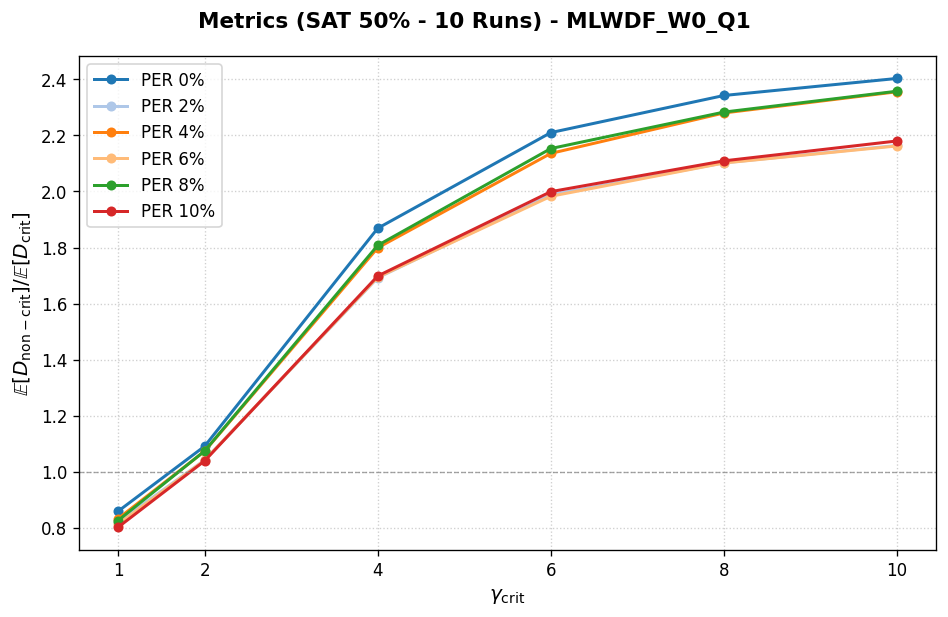


[PLOT] Renderizando curvas por PER para: MLWDF_W1_Q0 en SAT 50%
    [EXPORT] Guardado dataset para TikZ en: MLWDF_W1_Q0_SAT50_ratios_inverse_tikz.csv


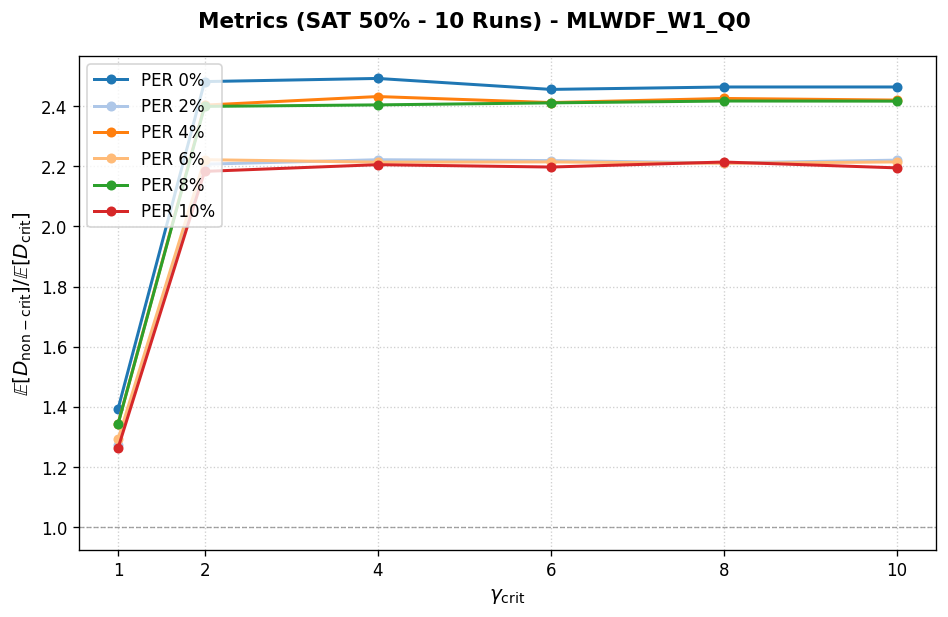


[PLOT] Renderizando curvas por PER para: MLWDF_W1_Q1 en SAT 50%
    [EXPORT] Guardado dataset para TikZ en: MLWDF_W1_Q1_SAT50_ratios_inverse_tikz.csv


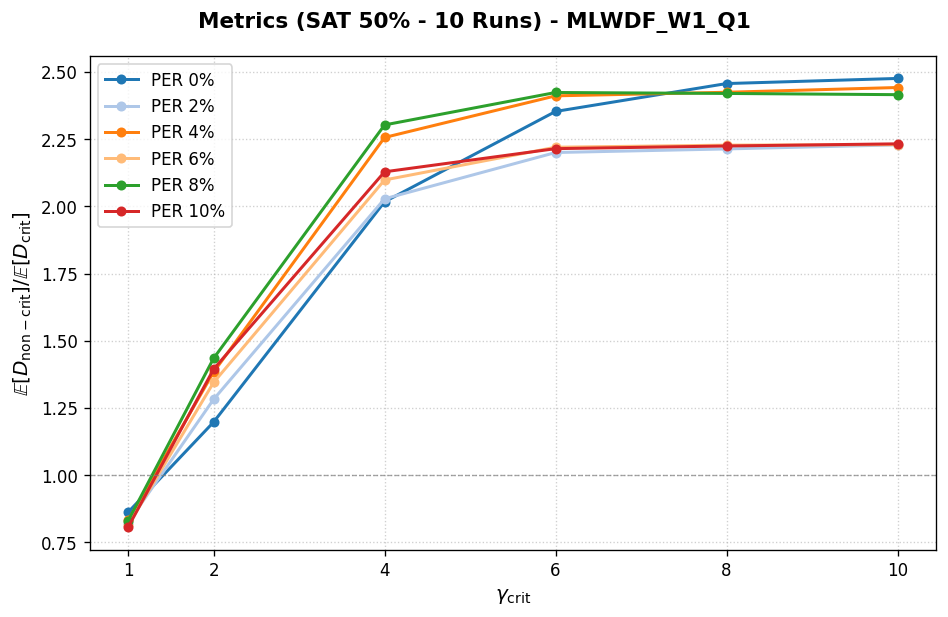

In [ ]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN DE RUTAS Y FORMATOS (MULTIPLEXADO DE ITERACIONES 0-4 Y 5-9)
# ==========================================
BASE_FOLDERNAMES = [
    "Poisson_2_1_conMDlogs_ALL",            # Iteraciones RUN0 a RUN4
    "Poisson_2_1_conMDlogs_ALL_ITERS5to10"  # Iteraciones RUN5 a RUN9
]
RESULTS_DIRS = [f"./results/{folder}" for folder in BASE_FOLDERNAMES]

SUFFIX_STREAM_0 = "1_1"  # Stream Crítico / Prioritario
SUFFIX_STREAM_1 = "1_2"  # Stream No Crítico

# schedulers_to_plot = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1"]
schedulers_to_plot = ["MLWDF_W1_Q1", "MLWDF_W1_Q1"]
per_values = [0, 2, 4, 6, 8, 10]

# ------------------------------------------
# PARÁMETROS EXPERIMENTALES SELECCIONABLES
# ------------------------------------------
TARGET_SAT = 50        # <-- CAMBIA AQUÍ: Elige la saturación a graficar (50, 70 o 90)
NUM_RUNS_TO_USE = 10   # <-- CAMBIA AQUÍ: Total de iteraciones multiplexadas (RUN0 a RUN9)

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """
    Extrae secuencialmente los timestamps sin mapear por ID,
    ajusta las longitudes al mínimo común y calcula el retraso.
    """
    if not cli_bytes or not srv_bytes:
        return np.nan
    
    # Extraer marcas de tiempo de transmisión (Cliente)
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try:
                tx_times.append(float(parts[0]))
            except ValueError:
                continue

    # Extraer marcas de tiempo de recepción (Servidor)
    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try:
                rx_times.append(float(parts[0]))
            except ValueError:
                continue

    # Si alguno de los dos archivos quedó completamente vacío
    if not tx_times or not rx_times:
        return np.nan

    # Determinar la longitud mínima para corregir cualquier descuadre de líneas
    if len(tx_times) != len(rx_times):
        print(f"    [WARNING] Desajuste de líneas: Cliente={len(tx_times)} vs Servidor={len(rx_times)}. Se recortará al mínimo común.")
    min_len = min(len(tx_times), len(rx_times))
    
    # Convertir a vectores de NumPy recortados al tamaño común
    tx_vector = np.array(tx_times[:min_len])
    rx_vector = np.array(rx_times[:min_len])
    
    # Resta vectorial directa
    valid_delays = rx_vector - tx_vector
    
    return np.mean(valid_delays) if valid_delays.size > 0 else np.nan

def process_tarfile_raw_runs(tar_path, max_runs):
    buffer_matrix = {}
    ignored_runs = 0
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = re.search(r"SAT\d+/(DELAY\d+_PER\d+/RUN\d+)", m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            
            # Filtrar run_id dinámicamente
            meta_match = re.search(r"RUN(\d+)", sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs:
                ignored_runs += 1
                continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    if ignored_runs > 0:
        print(f"    [INFO] Se omitieron {int(ignored_runs/4)} subcarpetas RUN por superar el límite estipulado.")

    print(f"    [PARSING] Procesando {len(buffer_matrix)} ejecuciones válidas encontradas en memoria RAM...")
    
    records = []
    for sim_key, bufs in buffer_matrix.items():
        meta_match = re.search(r"DELAY(\d+)_PER(\d+)/RUN(\d+)", sim_key)
        delay_val, per_val, run_id = map(int, meta_match.groups())
        
        d0 = fast_parse_and_calculate_delay(bufs['c0'], bufs['s0'])
        d1 = fast_parse_and_calculate_delay(bufs['c1'], bufs['s1'])
        print(f"    [DEBUG] RUN {run_id}: PER {per_val}% | D0={d0*1e-3:.4f} | D1={d1*1e-3:.4f}")
        # CAMBIO CLAVE: Cambiada la validación y el cálculo para dividir d0 / d1 en lugar de d1 / d0
        if not np.isnan(d0) and not np.isnan(d1) and d1 > 0:
            records.append((per_val, d0 / d1))
            
    return records

# ==========================================
# PROCESAMIENTO MATRICIAL MULTIPLEXADO CON FILTRADO Y LOGS
# ==========================================
aggregated_ratios = {}

all_compressed_packages = []
for r_dir in RESULTS_DIRS:
    if os.path.exists(r_dir):
        tar_pattern = os.path.join(r_dir, "**", f"SAT{TARGET_SAT}.tar.gz")
        all_compressed_packages.extend(sorted(glob.glob(tar_pattern, recursive=True)))
    else:
        print(f"[WARNING] No existe la carpeta de resultados: {r_dir}")

total_packages = len(all_compressed_packages)

print("="*80)
print(f"  INICIANDO PROCESAMIENTO MULTIPLEXADO FILTRADO POR SATURACIÓN")
print(f"  Carpetas origen: {', '.join(BASE_FOLDERNAMES)}")
print(f"  Saturación elegida: {TARGET_SAT}%")
print(f"  Límite: Máximo {NUM_RUNS_TO_USE} RUNs por caso (RUN0 a RUN{NUM_RUNS_TO_USE-1})")
print(f"  Paquetes detectados que coinciden: {total_packages}")
print("="*80)

for idx, tar_path in enumerate(all_compressed_packages, start=1):
    normalized_path = tar_path.replace("\\", "/")
    source_folder = next((b for b in BASE_FOLDERNAMES if b in normalized_path), "UNKNOWN")
    
    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
        if not match_mlwdf: continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
        if not match_basic: continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0

    if sched_label not in schedulers_to_plot:
        continue

    print(f"\n[{idx}/{total_packages}] -> ABRIENDO ({source_folder}): {os.path.basename(tar_path)}")
    print(f"    Mapeado como: Scheduler={sched_label} | Saturation={TARGET_SAT}% | Gamma={gamma_crit}")

    extracted_items = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
    
    for per_val, ratio in extracted_items:
        key = (sched_label, TARGET_SAT, gamma_crit, per_val)
        aggregated_ratios.setdefault(key, []).append(ratio)

print("\n" + "="*80)
print("  [PROCESAMIENTO COMPLETO] Reduciendo colecciones numéricas a medias...")
print("="*80)

final_data = {k: np.mean(v) for k, v in aggregated_ratios.items() if v}

# ==========================================
# COMPONENTE GRÁFICO Y EXPORTACIÓN
# ==========================================
if final_data:
    unique_scheds = sorted(list(set(k[0] for k in final_data.keys())))
    
    for current_sched in unique_scheds:
        print(f"\n[PLOT] Renderizando curvas por PER para: {current_sched} en SAT {TARGET_SAT}%")
        
        fig, ax = plt.subplots(figsize=(8, 5.2), dpi=120)
        fig.suptitle(f"Metrics (SAT {TARGET_SAT}% - {NUM_RUNS_TO_USE} Runs) - {current_sched}", fontsize=13, fontweight='bold', y=0.98)
        
        colors_palette = ["#1f77b4", "#aec7e8", "#ff7f0e", "#ffbb78", "#2ca02c", "#d62728"]
        legend_handles = []

        gammas = sorted(list(set(k[2] for k in final_data.keys() if k[0] == current_sched and k[1] == TARGET_SAT)))
        tikz_export_data = []

        for per_idx, current_per in enumerate(per_values):
            ratios_per_gamma = []
            
            for g in gammas:
                val = final_data.get((current_sched, TARGET_SAT, g, current_per), np.nan)
                ratios_per_gamma.append(val)
                if not np.isnan(val):
                    tikz_export_data.append({
                        'Saturation': TARGET_SAT, 'PER': current_per, 'Gamma': g, 'Ratio_Mean': val
                    })
            
            line, = ax.plot(gammas, ratios_per_gamma, color=colors_palette[per_idx], 
                            linewidth=1.8, marker='o', markersize=5, label=f"PER {current_per}%")
            legend_handles.append(line)
        
        ax.set_xlabel(r"$\gamma_{\mathrm{crit}}$", fontsize=12)
        # CAMBIO VISUAL: Se actualizó el formato matemático del eje Y para que muestre D_crit / D_non-crit
        ax.set_ylabel(r"$\mathbb{E}[D_{\mathrm{non-crit}}] / \mathbb{E}[D_{\mathrm{crit}}]$", fontsize=12)
        ax.set_xticks(gammas)
        ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
        ax.grid(True, linestyle=":", alpha=0.6)
        
        if tikz_export_data:
            csv_name = f"{current_sched}_SAT{TARGET_SAT}_ratios_inverse_tikz.csv"
            pd.DataFrame(tikz_export_data).to_csv(csv_name, index=False)
            print(f"    [EXPORT] Guardado dataset para TikZ en: {csv_name}")

        ax.legend(loc='upper left', frameon=True, fontsize=10)
        plt.tight_layout()
        plt.show()
else:
    print(f"❌ Error: No se encontraron datos para procesar en la saturación de {TARGET_SAT}%.")

In [ ]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN GENERAL
# ==========================================
BASE_FOLDERNAMES = [
    "Poisson_2_1_conMDlogs_ALL",            # Iteraciones RUN0 a RUN4
    "Poisson_2_1_conMDlogs_ALL_ITERS5to10"  # Iteraciones RUN5 a RUN9
]
RESULTS_DIRS = [f"./results/{folder}" for folder in BASE_FOLDERNAMES]

SUFFIX_STREAM_0 = "1_1"  # Stream 1: No Crítico
SUFFIX_STREAM_1 = "1_2"  # Stream 2: Crítico

TARGET_SATS = [50, 70, 90]
SCHEDULERS_TO_PROCESS = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1", "RR", "STBP"]
NUM_RUNS_TO_USE = 10

# Carpeta de salida coincidente con tu ruta de TikZ
OUTPUT_DIR = "./boxplot_cmp_sched_sims"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """Extrae timestamps y devuelve retardos en milisegundos."""
    if not cli_bytes or not srv_bytes: return []
    
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: tx_times.append(float(parts[0]))
            except ValueError: continue

    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: rx_times.append(float(parts[0]))
            except ValueError: continue

    if not tx_times or not rx_times: return []

    min_len = min(len(tx_times), len(rx_times))
    delays = np.array(rx_times[:min_len]) - np.array(tx_times[:min_len])
    valid_delays = delays[delays >= 0]
    return (valid_delays * 1e-3).tolist() 

def process_tarfile_raw_runs(tar_path, max_runs):
    """Extrae los retardos brutos por stream de cada corrida."""
    buffer_matrix = {}
    folder_regex = re.compile(r"SAT\d+/(DELAY\d+_PER10+/RUN\d+)")
    run_regex = re.compile(r"RUN(\d+)")
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = folder_regex.search(m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            meta_match = run_regex.search(sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs: continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    delays_stream0, delays_stream1 = [], []
    for sim_key, bufs in buffer_matrix.items():
        delays_stream0.extend(fast_parse_and_calculate_delay(bufs['c0'], bufs['s0']))
        delays_stream1.extend(fast_parse_and_calculate_delay(bufs['c1'], bufs['s1']))
            
    return delays_stream0, delays_stream1

def calculate_boxplot_stats(data):
    """Devuelve diccionario con lw, lq, med, uq, uw y avg."""
    if not data or len(data) == 0:
        return {'lw': 0.0, 'lq': 0.0, 'med': 0.0, 'uq': 0.0, 'uw': 0.0, 'avg': 0.0}
    
    arr = np.array(data)
    lq = float(np.percentile(arr, 25))
    med = float(np.percentile(arr, 50))
    uq = float(np.percentile(arr, 75))
    avg = float(np.mean(arr))
    iqr = uq - lq
    
    low_bound = lq - 1.5 * iqr
    high_bound = uq + 1.5 * iqr
    
    valid_low = arr[arr >= low_bound]
    lw = float(np.min(valid_low)) if len(valid_low) > 0 else float(np.min(arr))
    
    valid_high = arr[arr <= high_bound]
    uw = float(np.max(valid_high)) if len(valid_high) > 0 else float(np.max(arr))
    
    return {'lw': lw, 'lq': lq, 'med': med, 'uq': uq, 'uw': uw, 'avg': avg}

# ==========================================
# PROCESAMIENTO Y EXPORTACIÓN
# ==========================================
for target_sat in TARGET_SATS:
    print(f"\n==================== SAT {target_sat}% ====================")
    raw_data_storage = {}
    all_compressed_packages = []

    for r_dir in RESULTS_DIRS:
        if os.path.exists(r_dir):
            tar_pattern = os.path.join(r_dir, "**", f"SAT{target_sat}.tar.gz")
            all_compressed_packages.extend(sorted(glob.glob(tar_pattern, recursive=True)))

    for tar_path in all_compressed_packages:
        normalized_path = tar_path.replace("\\", "/")
        
        if "MLWDF" in normalized_path:
            match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
            if not match_mlwdf: continue
            sched_label = f"MLWDF_{match_mlwdf.group(1)}"
            gamma_crit = float(match_mlwdf.group(2))
        else:
            match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
            if not match_basic: continue
            sched_label = match_basic.group(1)
            gamma_crit = 1.0

        if sched_label not in SCHEDULERS_TO_PROCESS: continue

        d0_list, d1_list = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
        key = (sched_label, gamma_crit)
        if key not in raw_data_storage:
            raw_data_storage[key] = ([], [])
        raw_data_storage[key][0].extend(d0_list)
        raw_data_storage[key][1].extend(d1_list)

    # 1. MLWDF (Intercalado: Fila par = Stream 1, Fila impar = Stream 2)
    mlwdf_variants = sorted(list(set(k[0] for k in raw_data_storage.keys() if "MLWDF" in k[0])))
    for current_mlwdf in mlwdf_variants:
        variant_name = current_mlwdf.replace("MLWDF_", "")  # W0_Q1, W1_Q0, W1_Q1
        available_gammas = sorted([k[1] for k in raw_data_storage.keys() if k[0] == current_mlwdf])
        if not available_gammas: continue

        rows = []
        for g in available_gammas:
            d0, d1 = raw_data_storage.get((current_mlwdf, g), ([], []))
            s1_stats = calculate_boxplot_stats(d0)  # Stream 1
            s2_stats = calculate_boxplot_stats(d1)  # Stream 2
            
            # Fila par: Stream 1
            rows.append(s1_stats)
            # Fila impar: Stream 2
            rows.append(s2_stats)

        df_mlwdf = pd.DataFrame(rows)
        
        # Nombre de archivo solicitado (con sufijo _2)
        csv_filename = f"boxplot_stats_SAT{target_sat}_{variant_name}_2.csv"
        df_mlwdf.to_csv(os.path.join(OUTPUT_DIR, csv_filename), index=False)
        print(f"[OK] Generado: {csv_filename} ({len(df_mlwdf)} filas)")

    # 2. Referencias RR y STBP (Fila 0 = Stream 1, Fila 1 = Stream 2)
    sched_configs = [
        ("RR", f"boxplot_stats_RR_SAT{target_sat}_2.csv"),
        ("STBP", f"boxplot_stats_STBP_SAT{target_sat}.csv")
    ]
    
    for ref_sched, filename in sched_configs:
        if (ref_sched, 1.0) not in raw_data_storage: continue
        d0, d1 = raw_data_storage[(ref_sched, 1.0)]
        s1_stats = calculate_boxplot_stats(d0)  # Fila 0
        s2_stats = calculate_boxplot_stats(d1)  # Fila 1

        df_ref = pd.DataFrame([s1_stats, s2_stats])
        df_ref.to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
        print(f"[OK] Generado: {filename} (2 filas)")

  INICIANDO PROCESAMIENTO MULTIPLEXADO FILTRADO POR SATURACIÓN
  Carpetas origen: Poisson_2_1_conMDlogs_ALL, Poisson_2_1_conMDlogs_ALL_ITERS5to10
  Saturación elegida: 90%
  Límite: Máximo 10 RUNs por caso (RUN0 a RUN9)
  Paquetes detectados que coinciden: 40

[13/40] -> ABRIENDO (Poisson_2_1_conMDlogs_ALL): SAT90.tar.gz
    Mapeado como: Scheduler=MLWDF_W1_Q1 | Saturation=90% | Gamma=1.0


    [PARSING] Procesando 30 ejecuciones válidas encontradas en memoria RAM...
    [DEBUG] RUN 1: PER 6% | D0=63.0969 | D1=83.1924
    [DEBUG] RUN 4: PER 6% | D0=61.1330 | D1=79.5567
    [DEBUG] RUN 3: PER 6% | D0=64.2446 | D1=84.8748
    [DEBUG] RUN 0: PER 6% | D0=33.2237 | D1=41.8193
    [DEBUG] RUN 2: PER 6% | D0=37.0437 | D1=46.3722
    [WARNING] Desajuste de líneas: Cliente=120286 vs Servidor=120285. Se recortará al mínimo común.
    [DEBUG] RUN 1: PER 0% | D0=24.2814 | D1=29.0739
    [WARNING] Desajuste de líneas: Cliente=120286 vs Servidor=120285. Se recortará al mínimo común.
    [DEBUG] RUN 4: PER 0% | D0=24.6820 | D1=29.4444
    [WARNING] Desajuste de líneas: Cliente=120286 vs Servidor=120285. Se recortará al mínimo común.
    [DEBUG] RUN 3: PER 0% | D0=24.1957 | D1=28.8758
    [WARNING] Desajuste de líneas: Cliente=120286 vs Servidor=120285. Se recortará al mínimo común.
    [DEBUG] RUN 0: PER 0% | D0=23.8928 | D1=28.4753
    [WARNING] Desajuste de líneas: Cliente=120286 vs S

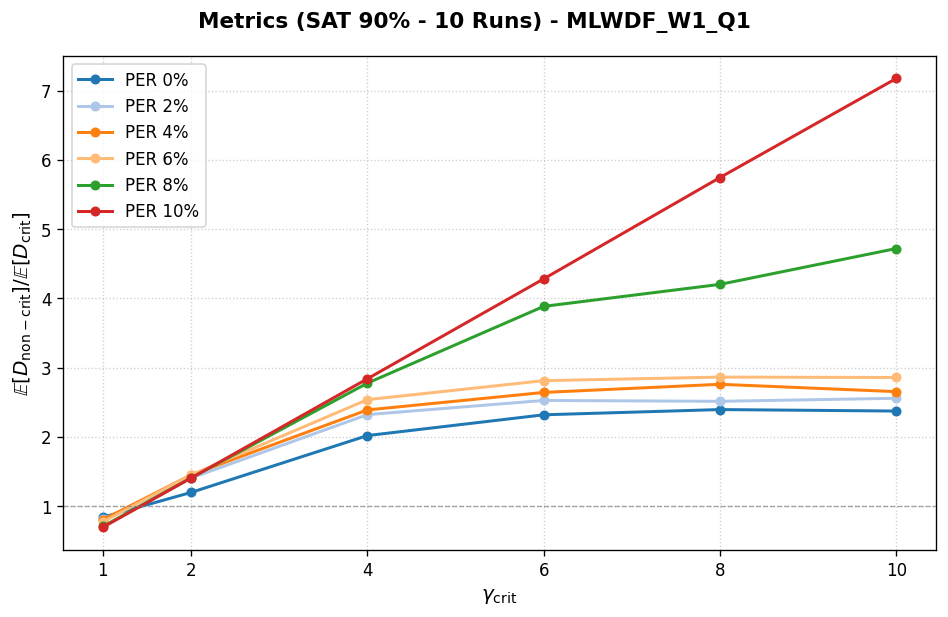

In [ ]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN DE RUTAS Y FORMATOS (MULTIPLEXADO DE ITERACIONES 0-4 Y 5-9)
# ==========================================
BASE_FOLDERNAMES = [
    "Poisson_2_1_conMDlogs_ALL",            # Iteraciones RUN0 a RUN4
    "Poisson_2_1_conMDlogs_ALL_ITERS5to10"  # Iteraciones RUN5 a RUN9
]
RESULTS_DIRS = [f"./results/{folder}" for folder in BASE_FOLDERNAMES]

SUFFIX_STREAM_0 = "1_1"  # Stream Crítico / Prioritario
SUFFIX_STREAM_1 = "1_2"  # Stream No Crítico

# schedulers_to_plot = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1"]
schedulers_to_plot = ["MLWDF_W1_Q1"]
per_values = [0, 2, 4, 6, 8, 10]

# ------------------------------------------
# PARÁMETROS EXPERIMENTALES SELECCIONABLES
# ------------------------------------------
TARGET_SAT = 90        # <-- CAMBIA AQUÍ: Elige la saturación a graficar (50, 70 o 90)
NUM_RUNS_TO_USE = 10   # <-- CAMBIA AQUÍ: Total de iteraciones multiplexadas (RUN0 a RUN9)

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """
    Extrae secuencialmente los timestamps sin mapear por ID,
    ajusta las longitudes al mínimo común y calcula el retraso.
    """
    if not cli_bytes or not srv_bytes:
        return np.nan
    
    # Extraer marcas de tiempo de transmisión (Cliente)
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try:
                tx_times.append(float(parts[0]))
            except ValueError:
                continue

    # Extraer marcas de tiempo de recepción (Servidor)
    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try:
                rx_times.append(float(parts[0]))
            except ValueError:
                continue

    # Si alguno de los dos archivos quedó completamente vacío
    if not tx_times or not rx_times:
        return np.nan

    # Determinar la longitud mínima para corregir cualquier descuadre de líneas
    if len(tx_times) != len(rx_times):
        print(f"    [WARNING] Desajuste de líneas: Cliente={len(tx_times)} vs Servidor={len(rx_times)}. Se recortará al mínimo común.")
    min_len = min(len(tx_times), len(rx_times))
    
    # Convertir a vectores de NumPy recortados al tamaño común
    tx_vector = np.array(tx_times[:min_len])
    rx_vector = np.array(rx_times[:min_len])
    
    # Resta vectorial directa
    valid_delays = rx_vector - tx_vector
    
    
    
    return np.mean(valid_delays) if valid_delays.size > 0 else np.nan

def process_tarfile_raw_runs(tar_path, max_runs):
    buffer_matrix = {}
    ignored_runs = 0
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = re.search(r"SAT\d+/(DELAY\d+_PER\d+/RUN\d+)", m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            
            # Filtrar run_id dinámicamente
            meta_match = re.search(r"RUN(\d+)", sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs:
                ignored_runs += 1
                continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    if ignored_runs > 0:
        print(f"    [INFO] Se omitieron {int(ignored_runs/4)} subcarpetas RUN por superar el límite estipulado.")

    print(f"    [PARSING] Procesando {len(buffer_matrix)} ejecuciones válidas encontradas en memoria RAM...")
    
    records = []
    for sim_key, bufs in buffer_matrix.items():
        meta_match = re.search(r"DELAY(\d+)_PER(\d+)/RUN(\d+)", sim_key)
        delay_val, per_val, run_id = map(int, meta_match.groups())
        
        d0 = fast_parse_and_calculate_delay(bufs['c0'], bufs['s0'])
        d1 = fast_parse_and_calculate_delay(bufs['c1'], bufs['s1'])
        print(f"    [DEBUG] RUN {run_id}: PER {per_val}% | D0={d0*1e-3:.4f} | D1={d1*1e-3:.4f}")
        
        # CAMBIO CLAVE: Cambiada la validación y el cálculo para dividir d0 / d1 en lugar de d1 / d0
        if not np.isnan(d0) and not np.isnan(d1) and d1 > 0:
            records.append((per_val, d0 / d1))
            
    return records  # <--- CORRECCIÓN: Esta línea estaba comentada

# ==========================================
# PROCESAMIENTO MATRICIAL MULTIPLEXADO CON FILTRADO Y LOGS
# ==========================================
aggregated_ratios = {}

all_compressed_packages = []
for r_dir in RESULTS_DIRS:
    if os.path.exists(r_dir):
        tar_pattern = os.path.join(r_dir, "**", f"SAT{TARGET_SAT}.tar.gz")
        all_compressed_packages.extend(sorted(glob.glob(tar_pattern, recursive=True)))
    else:
        print(f"[WARNING] No existe la carpeta de resultados: {r_dir}")

total_packages = len(all_compressed_packages)

print("="*80)
print(f"  INICIANDO PROCESAMIENTO MULTIPLEXADO FILTRADO POR SATURACIÓN")
print(f"  Carpetas origen: {', '.join(BASE_FOLDERNAMES)}")
print(f"  Saturación elegida: {TARGET_SAT}%")
print(f"  Límite: Máximo {NUM_RUNS_TO_USE} RUNs por caso (RUN0 a RUN{NUM_RUNS_TO_USE-1})")
print(f"  Paquetes detectados que coinciden: {total_packages}")
print("="*80)

for idx, tar_path in enumerate(all_compressed_packages, start=1):
    normalized_path = tar_path.replace("\\", "/")
    source_folder = next((b for b in BASE_FOLDERNAMES if b in normalized_path), "UNKNOWN")
    
    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
        if not match_mlwdf: continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
        if not match_basic: continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0

    if sched_label not in schedulers_to_plot:
        continue

    print(f"\n[{idx}/{total_packages}] -> ABRIENDO ({source_folder}): {os.path.basename(tar_path)}")
    print(f"    Mapeado como: Scheduler={sched_label} | Saturation={TARGET_SAT}% | Gamma={gamma_crit}")

    extracted_items = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
    
    for per_val, ratio in extracted_items:
        key = (sched_label, TARGET_SAT, gamma_crit, per_val)
        aggregated_ratios.setdefault(key, []).append(ratio)

print("\n" + "="*80)
print("  [PROCESAMIENTO COMPLETO] Reduciendo colecciones numéricas a medias...")
print("="*80)

final_data = {k: np.mean(v) for k, v in aggregated_ratios.items() if v}

# ==========================================
# COMPONENTE GRÁFICO Y EXPORTACIÓN
# ==========================================
if final_data:
    unique_scheds = sorted(list(set(k[0] for k in final_data.keys())))
    
    for current_sched in unique_scheds:
        print(f"\n[PLOT] Renderizando curvas por PER para: {current_sched} en SAT {TARGET_SAT}%")
        
        fig, ax = plt.subplots(figsize=(8, 5.2), dpi=120)
        fig.suptitle(f"Metrics (SAT {TARGET_SAT}% - {NUM_RUNS_TO_USE} Runs) - {current_sched}", fontsize=13, fontweight='bold', y=0.98)
        
        colors_palette = ["#1f77b4", "#aec7e8", "#ff7f0e", "#ffbb78", "#2ca02c", "#d62728"]
        legend_handles = []

        gammas = sorted(list(set(k[2] for k in final_data.keys() if k[0] == current_sched and k[1] == TARGET_SAT)))
        tikz_export_data = []

        for per_idx, current_per in enumerate(per_values):
            ratios_per_gamma = []
            
            for g in gammas:
                val = final_data.get((current_sched, TARGET_SAT, g, current_per), np.nan)
                ratios_per_gamma.append(val)
                if not np.isnan(val):
                    tikz_export_data.append({
                        'Saturation': TARGET_SAT, 'PER': current_per, 'Gamma': g, 'Ratio_Mean': val
                    })
            
            line, = ax.plot(gammas, ratios_per_gamma, color=colors_palette[per_idx % len(colors_palette)], 
                            linewidth=1.8, marker='o', markersize=5, label=f"PER {current_per}%")
            legend_handles.append(line)
        
        ax.set_xlabel(r"$\gamma_{\mathrm{crit}}$", fontsize=12)
        # CAMBIO VISUAL: Se actualizó el formato matemático del eje Y para que muestre D_crit / D_non-crit
        ax.set_ylabel(r"$\mathbb{E}[D_{\mathrm{non-crit}}] / \mathbb{E}[D_{\mathrm{crit}}]$", fontsize=12)
        ax.set_xticks(gammas)
        ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
        ax.grid(True, linestyle=":", alpha=0.6)
        
        if tikz_export_data:
            csv_name = f"{current_sched}_SAT{TARGET_SAT}_ratios_inverse_tikz.csv"
            pd.DataFrame(tikz_export_data).to_csv(csv_name, index=False)
            print(f"    [EXPORT] Guardado dataset para TikZ en: {csv_name}")

        ax.legend(loc='upper left', frameon=True, fontsize=10)
        plt.tight_layout()
        plt.show()
else:
    print(f"❌ Error: No se encontraron datos para procesar en la saturación de {TARGET_SAT}%.")

[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 1.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 10.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 2.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 4.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 6.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 8.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 1.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 10.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 2.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 4.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 6.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 8.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q1 | Gamma: 1.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q1 | Gamma: 10.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q1 | Gamma: 2.0
[EXTRAC

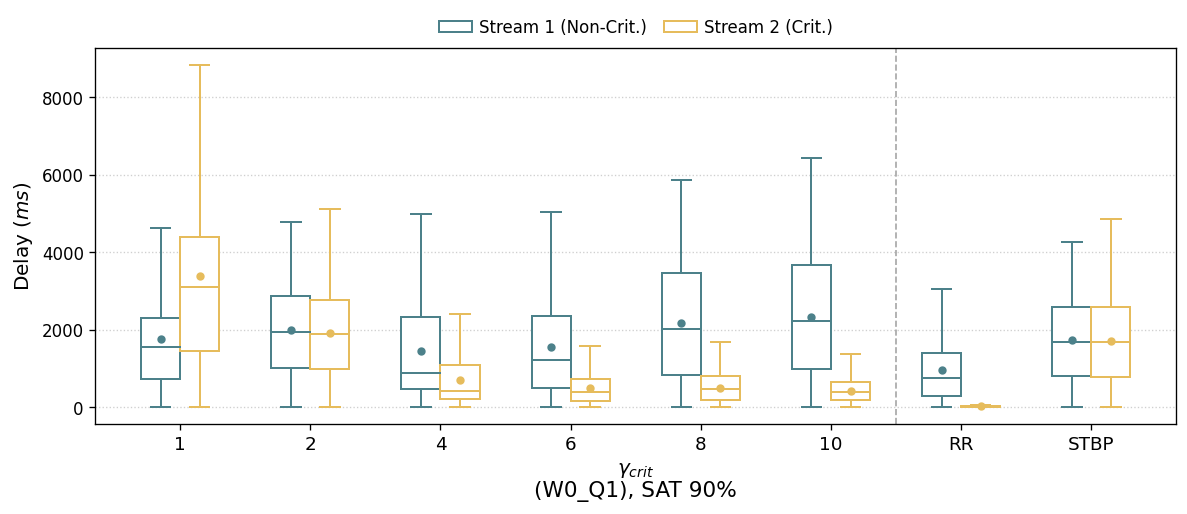

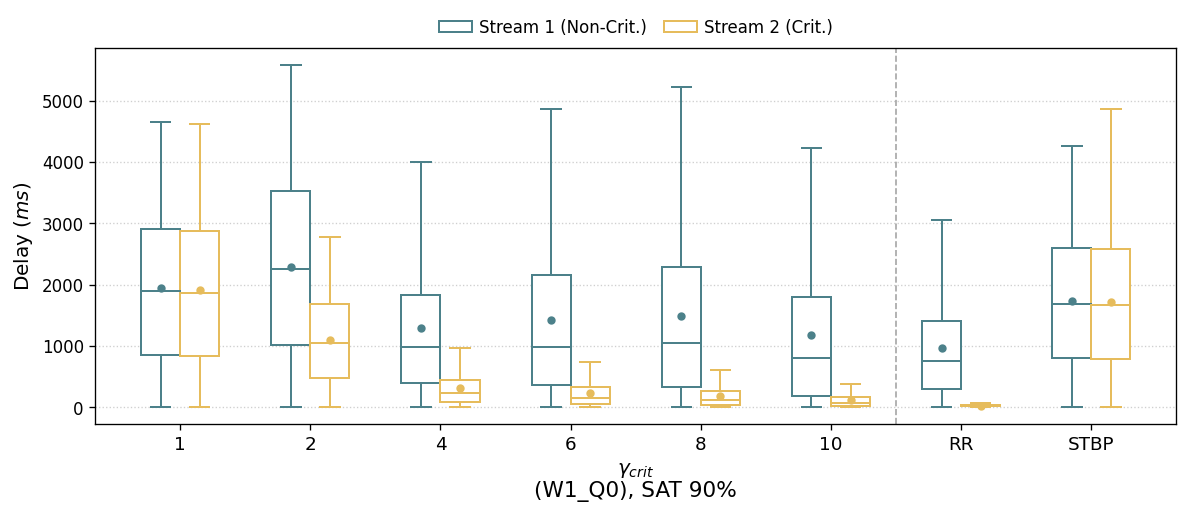

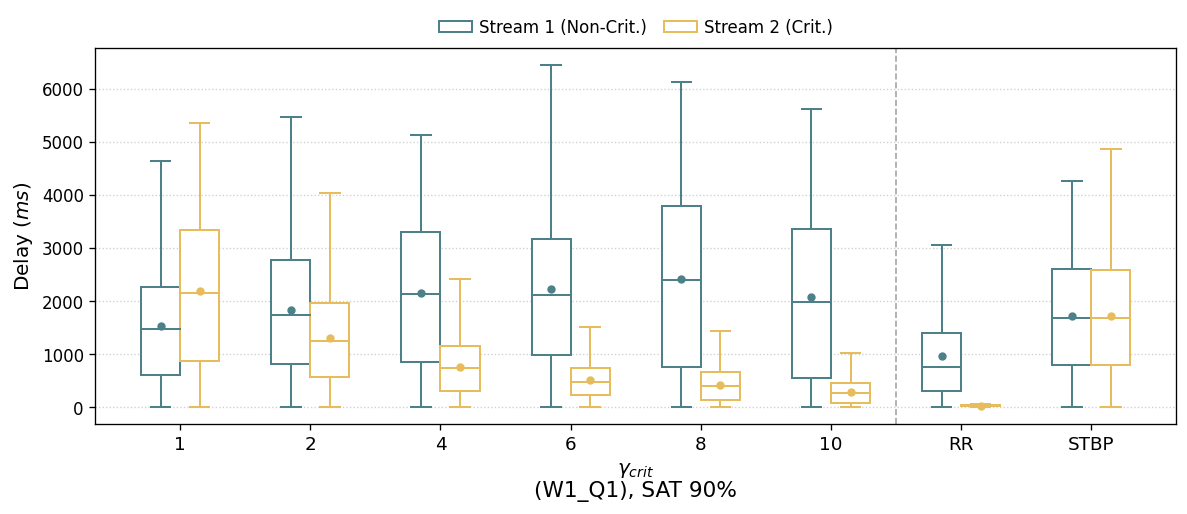

In [ ]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN DE RUTAS Y FORMATOS (MULTIPLEXADO DE ITERACIONES 0-4 Y 5-9)
# ==========================================
BASE_FOLDERNAMES = [
    "Poisson_2_1_conMDlogs_ALL",            # Iteraciones RUN0 a RUN4
    "Poisson_2_1_conMDlogs_ALL_ITERS5to10"  # Iteraciones RUN5 a RUN9
]
RESULTS_DIRS = [f"./results/{folder}" for folder in BASE_FOLDERNAMES]

SUFFIX_STREAM_0 = "1_1"  # Stream No Critico (Stream 1 en tu imagen)
SUFFIX_STREAM_1 = "1_2"  # Stream Critico / Prioritario (Stream 2 en tu imagen)

# Queremos procesar todos los schedulers para poder pintar RR y STBP al final
schedulers_to_plot = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1", "RR", "STBP"]
# schedulers_to_plot = ["MLWDF_W1_Q1"]
TARGET_SAT = 90        # <-- Ajustado a 90% (o 50, 70)
NUM_RUNS_TO_USE = 10   # <-- Usamos todas las 10 iteraciones multiplexadas (RUN0 a RUN9)

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """Extrae secuencialmente los timestamps y calcula los delays individuales."""
    if not cli_bytes or not srv_bytes: return []
    
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: tx_times.append(float(parts[0]))
            except ValueError: continue

    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: rx_times.append(float(parts[0]))
            except ValueError: continue

    if not tx_times or not rx_times: return []

    min_len = min(len(tx_times), len(rx_times))
    tx_vector = np.array(tx_times[:min_len])
    rx_vector = np.array(rx_times[:min_len])
    
    delays = rx_vector - tx_vector
    valid_delays = delays[delays >= 0]
    
    # OJO: Si tus logs están en segundos, multiplicamos por 1000 para pasar a milisegundos (ms)
    return (valid_delays * 1e-3).tolist() 

def process_tarfile_raw_runs(tar_path, max_runs):
    """Procesa el paquete comprimido extrayendo todos los delays brutos por stream."""
    buffer_matrix = {}
    folder_regex = re.compile(r"SAT\d+/(DELAY\d+_PER10+/RUN\d+)")
    run_regex = re.compile(r"RUN(\d+)")
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = folder_regex.search(m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            meta_match = run_regex.search(sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs: continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    delays_stream0 = []
    delays_stream1 = []
    
    for sim_key, bufs in buffer_matrix.items():
        d0 = fast_parse_and_calculate_delay(bufs['c0'], bufs['s0'])
        d1 = fast_parse_and_calculate_delay(bufs['c1'], bufs['s1'])
        delays_stream0.extend(d0)
        delays_stream1.extend(d1)
            
    return delays_stream0, delays_stream1

# ==========================================
# EXTRACCIÓN MULTIPLEXADA DE DATOS (ITER 0-4 Y ITER 5-9)
# ==========================================
raw_data_storage = {} # Estructura: {(sched, gamma): (all_d0, all_d1)}

all_compressed_packages = []
for r_dir in RESULTS_DIRS:
    if os.path.exists(r_dir):
        tar_pattern = os.path.join(r_dir, "**", f"SAT{TARGET_SAT}.tar.gz")
        all_compressed_packages.extend(sorted(glob.glob(tar_pattern, recursive=True)))
    else:
        print(f"[WARNING] No existe la carpeta de resultados: {r_dir}")

for tar_path in all_compressed_packages:
    normalized_path = tar_path.replace("\\", "/")
    source_folder = next((b for b in BASE_FOLDERNAMES if b in normalized_path), "UNKNOWN")
    
    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
        if not match_mlwdf: continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
        if not match_basic: continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0 # Para RR y STBP asignamos 1.0 por defecto temporalmente

    if sched_label not in schedulers_to_plot: continue

    print(f"[EXTRACTING] ({source_folder}) {sched_label} | Gamma: {gamma_crit}")
    d0_list, d1_list = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
    
    key = (sched_label, gamma_crit)
    if key not in raw_data_storage:
        raw_data_storage[key] = ([], [])
    raw_data_storage[key][0].extend(d0_list)
    raw_data_storage[key][1].extend(d1_list)

# ==========================================
# RENDERIZADO DE BOXPLOTS ESTILO PAPER
# ==========================================
# Vamos a generar una gráfica por cada variante de MLWDF encontrada (e.g., W1_Q0, W1_Q1)
mlwdf_variants = sorted(list(set(k[0] for k in raw_data_storage.keys() if "MLWDF" in k[0])))

for current_mlwdf in mlwdf_variants:
    # Extraer y ordenar las gammas disponibles para este MLWDF
    available_gammas = sorted([k[1] for k in raw_data_storage.keys() if k[0] == current_mlwdf])
    
    if not available_gammas: continue
    
    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
    
    # Configuración de posiciones en el Eje X para el agrupamiento doble (Side-by-Side)
    # Dejamos espacio al final para RR y STBP
    total_configurations = len(available_gammas) + 2 # Gammas + RR + STBP
    x_positions = np.arange(total_configurations)
    
    width = 0.3 # Ancho de las cajas
    
    # Listas para almacenar los datos finales que irán al boxplot
    data_non_crit = []
    data_crit = []
    x_labels = []
    
    # 1. Añadir los datos del MLWDF actual recorriendo sus gammas
    for g in available_gammas:
        d0, d1 = raw_data_storage.get((current_mlwdf, g), ([], []))
        data_crit.append(d1 if d1 else [0])
        data_non_crit.append(d0 if d0 else [0])
        # Formatear la etiqueta del eje X (si es entero, quitar el .0)
        x_labels.append(str(int(g)) if g.is_integer() else str(g))
        
    # 2. Añadir de forma fija las referencias de RR y STBP al final si existen
    for ref_sched in ["RR", "STBP"]:
        d0, d1 = raw_data_storage.get((ref_sched, 1.0), ([], []))
        data_crit.append(d1 if d1 else [0])
        data_non_crit.append(d0 if d0 else [0])
        x_labels.append(ref_sched)

    # Definición de colores idénticos a tu referencia de TikZ/Matplotlib
    color_non_crit = "#4c818a" # Azul verdoso opaco
    color_crit = "#e6bc5c"     # Dorado/Amarillo ocre
    
    # Dibujar Boxplots del Stream 1 (Non-Critical) desplazas a la izquierda
    bp1 = ax.boxplot(data_non_crit, positions=x_positions - 1.5*width/2, widths=width,
                     patch_artist=True, showmeans=True, showfliers=False,
                     boxprops=dict(facecolor='white', color=color_non_crit, linewidth=1.2),
                     capprops=dict(color=color_non_crit, linewidth=1.2),
                     whiskerprops=dict(color=color_non_crit, linewidth=1.2),
                     medianprops=dict(color=color_non_crit, linewidth=1.2),
                     meanprops=dict(marker='o', markerfacecolor=color_non_crit, markeredgecolor=color_non_crit, markersize=4))

    # Dibujar Boxplots del Stream 2 (Critical) desplazadas a la derecha
    bp2 = ax.boxplot(data_crit, positions=x_positions + 1.5*width/2, widths=width,
                     patch_artist=True, showmeans=True, showfliers=False,
                     boxprops=dict(facecolor='white', color=color_crit, linewidth=1.2),
                     capprops=dict(color=color_crit, linewidth=1.2),
                     whiskerprops=dict(color=color_crit, linewidth=1.2),
                     medianprops=dict(color=color_crit, linewidth=1.2),
                     meanprops=dict(marker='o', markerfacecolor=color_crit, markeredgecolor=color_crit, markersize=4))

    # Estética del Eje X y Y
    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, fontsize=11)
    ax.set_xlabel(r"$\gamma_{crit}$", fontsize=12)
    ax.set_ylabel("Delay ($ms$)", fontsize=12)
    
    # Línea divisoria vertical punteada antes de las referencias estáticas (RR y STBP)
    # Se posiciona justo en medio del último valor de gamma y el primer scheduler estático
    divider_x = len(available_gammas) - 0.5
    ax.axvline(x=divider_x, color='gray', linestyle='--', linewidth=1.0, alpha=0.7)
    
    # Rejilla de fondo horizontal clara
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    
    # Título limpio en la parte inferior o superior (Estilo subfigura (a) (b))
    label_clean = current_mlwdf.replace("MLWDF_", "")
    ax.set_title(f"({label_clean}), SAT {TARGET_SAT}%", fontsize=13, y=-0.22, fontweight='normal')

    # Leyenda superior idéntica a la imagen
    ax.legend([bp1["boxes"][0], bp2["boxes"][0]], 
              ['Stream 1 (Non-Crit.)', 'Stream 2 (Crit.)'], 
              loc='upper center', bbox_to_anchor=(0.5, 1.12),
              ncol=2, frameon=False, fontsize=10, handletextpad=0.4, columnspacing=1.0)

    plt.tight_layout()
    plt.show()


STARTING DATA EXTRACTION (PER = 8%)
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W0_Q1 | Gamma: 1.0 | PER: 8%


    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W0_Q1 | Gamma: 10.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W0_Q1 | Gamma: 2.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W0_Q1 | Gamma: 4.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W0_Q1 | Gamma: 6.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W0_Q1 | Gamma: 8.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W1_Q0 | Gamma: 1.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poisson_2_1_conMDlogs_ALL | MLWDF_W1_Q0 | Gamma: 10.0 | PER: 8%
    Stream 1: 307395 samples | Stream 2: 158355 samples
[EXTRACTING] Poiss

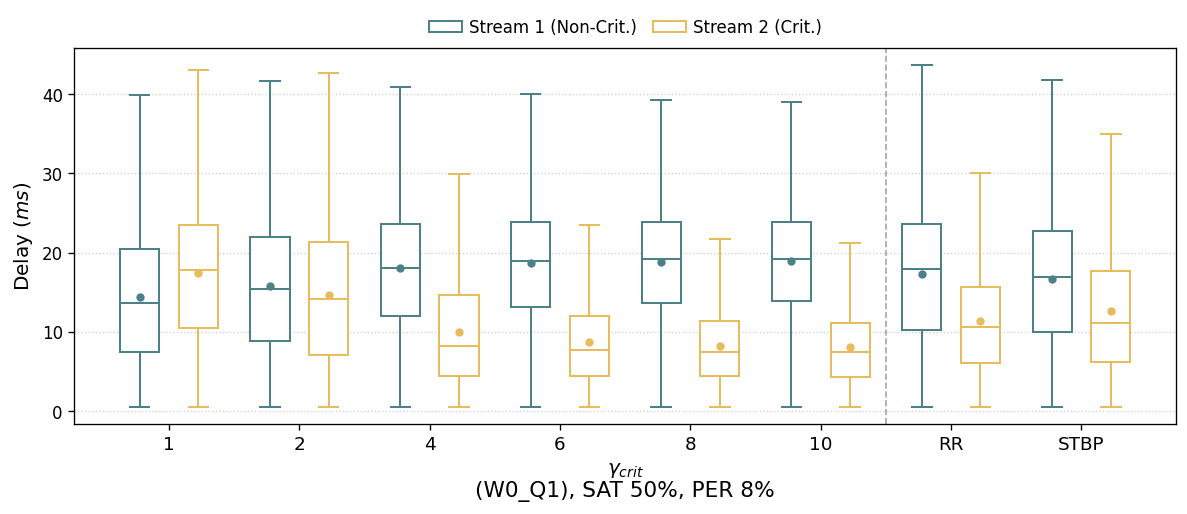

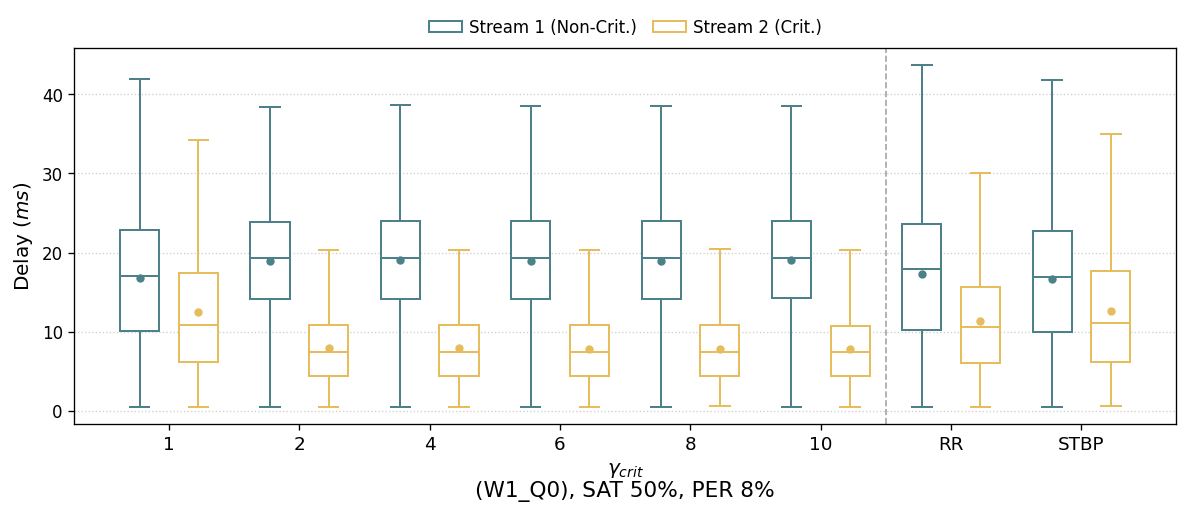

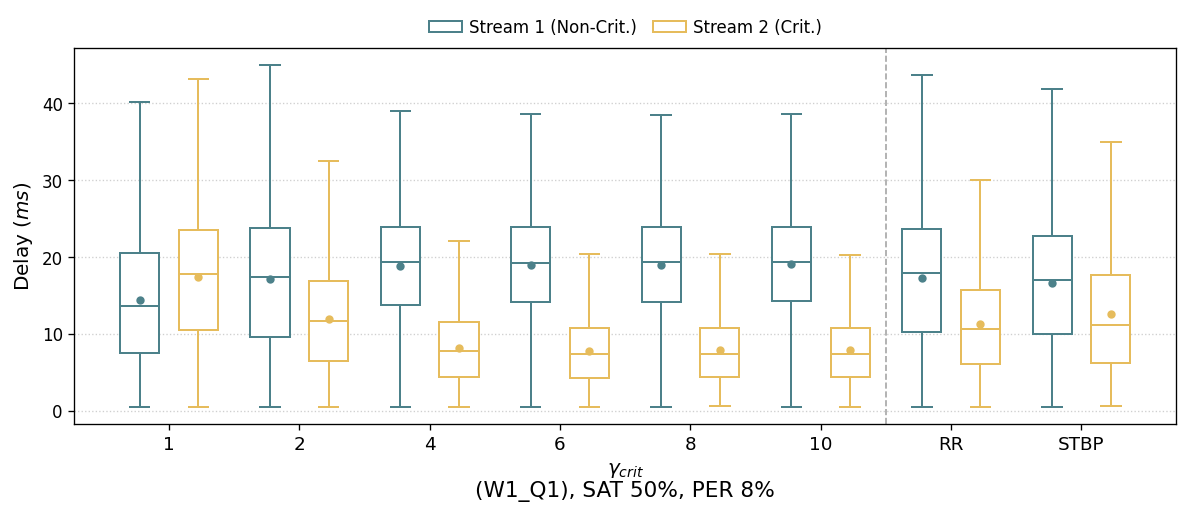


PROCESSING FINISHED
MLWDF variants: 3
CSV files generated: 3
  -> ./csv_statistics/boxplot_statistics_MLWDF_W0_Q1_SAT50_PER8.csv
  -> ./csv_statistics/boxplot_statistics_MLWDF_W1_Q0_SAT50_PER8.csv
  -> ./csv_statistics/boxplot_statistics_MLWDF_W1_Q1_SAT50_PER8.csv


In [8]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURACION
# ============================================================

BASE_FOLDERNAMES = [
    "Poisson_2_1_conMDlogs_ALL",           # RUN0 a RUN4
    "Poisson_2_1_conMDlogs_ALL_ITERS5to10" # RUN5 a RUN9
]

RESULTS_DIRS = [
    f"./results/{folder}" for folder in BASE_FOLDERNAMES
]

SUFFIX_STREAM_0 = "1_1"  # Stream 1: Non-Critical
SUFFIX_STREAM_1 = "1_2"  # Stream 2: Critical

schedulers_to_plot = [
    "MLWDF_W1_Q0",
    "MLWDF_W1_Q1",
    "MLWDF_W0_Q1",
    "RR",
    "STBP"
]

TARGET_SAT = 50
TARGET_PER = 8          # <-- PER fijado al 8%
NUM_RUNS_TO_USE = 10

OUTPUT_DIR = "./csv_statistics"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. EXTRACCION Y CALCULO DE DELAYS
# ============================================================

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """
    Extrae timestamps de los logs del cliente y servidor.
    Utiliza exclusivamente el mínimo número de timestamps
    disponibles en ambos logs para evitar intentar calcular
    retardos de paquetes que no aparecen en el servidor.
    Los timestamps se emparejan por posición.
    """
    if not cli_bytes or not srv_bytes:
        return []

    def extract_timestamps(log_bytes):
        timestamps = []
        for line in log_bytes.decode("utf-8", errors="ignore").splitlines():
            parts = line.split()
            if not parts:
                continue
            try:
                timestamps.append(float(parts[0]))
            except ValueError:
                continue
        return timestamps

    tx_times = extract_timestamps(cli_bytes)
    rx_times = extract_timestamps(srv_bytes)

    min_len = min(len(tx_times), len(rx_times))
    if min_len == 0:
        return []

    tx_vector = np.asarray(tx_times[:min_len], dtype=float)
    rx_vector = np.asarray(rx_times[:min_len], dtype=float)

    delays = rx_vector - tx_vector
    valid_delays = delays[delays >= 0]

    return (valid_delays * 1e-3).tolist()


# ============================================================
# 3. PROCESAMIENTO DE ARCHIVOS TAR.GZ
# ============================================================

def process_tarfile_raw_runs(tar_path, max_runs, target_per):
    buffer_matrix = {}

    # Filtra exactamente por el PER deseado (soporta PER8 y PER08)
    folder_regex = re.compile(
        rf"SAT\d+/(DELAY\d+_PER0*{target_per}/RUN\d+)"
    )
    run_regex = re.compile(r"RUN(\d+)")

    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile():
                continue

            match_folder = folder_regex.search(m.name)
            if not match_folder:
                continue

            sim_key = match_folder.group(1)
            meta_match = run_regex.search(sim_key)

            if meta_match and int(meta_match.group(1)) >= max_runs:
                continue

            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {
                    "c0": None,
                    "s0": None,
                    "c1": None,
                    "s1": None
                }

            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename:
                    buffer_matrix[sim_key]["c0"] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename:
                    buffer_matrix[sim_key]["c1"] = tar.extractfile(m).read()

            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename:
                    buffer_matrix[sim_key]["s0"] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename:
                    buffer_matrix[sim_key]["s1"] = tar.extractfile(m).read()

    delays_stream0 = []
    delays_stream1 = []

    for sim_key, bufs in buffer_matrix.items():
        d0 = fast_parse_and_calculate_delay(bufs["c0"], bufs["s0"])
        d1 = fast_parse_and_calculate_delay(bufs["c1"], bufs["s1"])
        delays_stream0.extend(d0)
        delays_stream1.extend(d1)

    return delays_stream0, delays_stream1


# ============================================================
# 4. EXTRACCION MULTIPLEXADA DE RESULTADOS
# ============================================================

raw_data_storage = {}
all_compressed_packages = []

for r_dir in RESULTS_DIRS:
    if os.path.exists(r_dir):
        tar_pattern = os.path.join(
            r_dir,
            "**",
            f"SAT{TARGET_SAT}.tar.gz"
        )
        all_compressed_packages.extend(
            sorted(glob.glob(tar_pattern, recursive=True))
        )
    else:
        print(f"[WARNING] No existe la carpeta: {r_dir}")

print("\n============================================")
print(f"STARTING DATA EXTRACTION (PER = {TARGET_PER}%)")
print("============================================")

for tar_path in all_compressed_packages:
    normalized_path = tar_path.replace("\\", "/")
    source_folder = next(
        (b for b in BASE_FOLDERNAMES if b in normalized_path),
        "UNKNOWN"
    )

    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(
            r"MLWDF/([^/]+)/GAMMA_CRIT_([0-9.eE+-]+)/",
            normalized_path
        )
        if not match_mlwdf:
            continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(
            r"([^/]+)/SAT\d+\.tar\.gz$",
            normalized_path
        )
        if not match_basic:
            continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0

    if sched_label not in schedulers_to_plot:
        continue

    print(
        f"[EXTRACTING] {source_folder} | "
        f"{sched_label} | Gamma: {gamma_crit} | PER: {TARGET_PER}%"
    )

    d0_list, d1_list = process_tarfile_raw_runs(
        tar_path,
        max_runs=NUM_RUNS_TO_USE,
        target_per=TARGET_PER
    )

    key = (sched_label, gamma_crit)
    if key not in raw_data_storage:
        raw_data_storage[key] = ([], [])

    raw_data_storage[key][0].extend(d0_list)
    raw_data_storage[key][1].extend(d1_list)

    print(
        f"    Stream 1: {len(d0_list)} samples | "
        f"Stream 2: {len(d1_list)} samples"
    )


# ============================================================
# 5. CALCULO DE ESTADISTICOS DEL BOXPLOT
# ============================================================

def calculate_boxplot_statistics(data):
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]

    if len(data) == 0:
        return None

    lq, med, uq = np.percentile(data, [25, 50, 75])
    iqr = uq - lq

    lower_limit = lq - 1.5 * iqr
    upper_limit = uq + 1.5 * iqr

    lw = np.min(data[data >= lower_limit])
    uw = np.max(data[data <= upper_limit])

    return {
        "lw": lw,
        "lq": lq,
        "med": med,
        "uq": uq,
        "uw": uw,
        "avg": np.mean(data),
        "max": np.max(data),
        "min": np.min(data)
    }


# ============================================================
# 6. EXPORTACION CSV CON LAS COLUMNAS SOLICITADAS
# ============================================================

def export_boxplot_statistics(raw_data_storage, current_mlwdf, output_dir):
    records = []

    mlwdf_keys = sorted(
        [key for key in raw_data_storage if key[0] == current_mlwdf],
        key=lambda x: x[1]
    )

    keys_to_export = mlwdf_keys + [
        (scheduler, 1.0)
        for scheduler in ["RR", "STBP"]
        if (scheduler, 1.0) in raw_data_storage
    ]

    width = 0.3

    for x_position, (scheduler, gamma) in enumerate(keys_to_export):
        d0, d1 = raw_data_storage[(scheduler, gamma)]

        streams = [
            (1, d0, x_position - 1.5 * width / 2),
            (2, d1, x_position + 1.5 * width / 2)
        ]

        for stream_number, data, xaux in streams:
            stats = calculate_boxplot_statistics(data)
            if stats is None:
                print(
                    f"[WARNING] No data: {scheduler}, "
                    f"gamma={gamma}, stream={stream_number}"
                )
                continue

            records.append({
                "gamma": gamma,
                "lw": stats["lw"],
                "lq": stats["lq"],
                "med": stats["med"],
                "uq": stats["uq"],
                "uw": stats["uw"],
                "xaux": xaux,
                "avg": stats["avg"],
                "max": stats["max"],
                "min": stats["min"],
                "stream": stream_number,
                "scheduler": scheduler
            })

    columns = [
        "gamma", "lw", "lq", "med", "uq", "uw",
        "xaux", "avg", "max", "min", "stream", "scheduler"
    ]

    df = pd.DataFrame(records, columns=columns)

    output_path = os.path.join(
        output_dir,
        f"boxplot_statistics_{current_mlwdf}_SAT{TARGET_SAT}_PER{TARGET_PER}.csv"
    )

    df.to_csv(
        output_path,
        index=False,
        sep=",",
        decimal=".",
        float_format="%.10g"
    )

    print("\n============================================")
    print("[CSV GENERATED]")
    print("============================================")
    print(f"File: {output_path}")
    print(f"Total boxplots: {len(df)}")

    return output_path


# ============================================================
# 7. GENERACION DE UN CSV POR VARIANTE MLWDF
# ============================================================

mlwdf_variants = sorted(
    set(key[0] for key in raw_data_storage.keys() if "MLWDF" in key[0])
)

generated_csvs = []
for current_mlwdf in mlwdf_variants:
    csv_path = export_boxplot_statistics(
        raw_data_storage,
        current_mlwdf,
        OUTPUT_DIR
    )
    generated_csvs.append(csv_path)


# ============================================================
# 8. RENDERIZADO DE BOXPLOTS CON MATPLOTLIB
# ============================================================

for current_mlwdf in mlwdf_variants:
    available_gammas = sorted([
        key[1] for key in raw_data_storage.keys() if key[0] == current_mlwdf
    ])

    if not available_gammas:
        continue

    fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)

    total_configurations = len(available_gammas) + 2
    x_positions = np.arange(total_configurations)
    width = 0.3

    data_non_crit = []
    data_crit = []
    x_labels = []

    for g in available_gammas:
        d0, d1 = raw_data_storage.get((current_mlwdf, g), ([], []))
        data_non_crit.append(d0 if d0 else [np.nan])
        data_crit.append(d1 if d1 else [np.nan])
        x_labels.append(str(int(g)) if g.is_integer() else str(g))

    for ref_sched in ["RR", "STBP"]:
        d0, d1 = raw_data_storage.get((ref_sched, 1.0), ([], []))
        data_non_crit.append(d0 if d0 else [np.nan])
        data_crit.append(d1 if d1 else [np.nan])
        x_labels.append(ref_sched)

    color_non_crit = "#4c818a"
    color_crit = "#e6bc5c"

    bp1 = ax.boxplot(
        data_non_crit,
        positions=x_positions - 1.5 * width / 2,
        widths=width,
        patch_artist=True,
        showmeans=True,
        showfliers=False,
        boxprops=dict(facecolor="white", color=color_non_crit, linewidth=1.2),
        capprops=dict(color=color_non_crit, linewidth=1.2),
        whiskerprops=dict(color=color_non_crit, linewidth=1.2),
        medianprops=dict(color=color_non_crit, linewidth=1.2),
        meanprops=dict(marker="o", markerfacecolor=color_non_crit, markeredgecolor=color_non_crit, markersize=4)
    )

    bp2 = ax.boxplot(
        data_crit,
        positions=x_positions + 1.5 * width / 2,
        widths=width,
        patch_artist=True,
        showmeans=True,
        showfliers=False,
        boxprops=dict(facecolor="white", color=color_crit, linewidth=1.2),
        capprops=dict(color=color_crit, linewidth=1.2),
        whiskerprops=dict(color=color_crit, linewidth=1.2),
        medianprops=dict(color=color_crit, linewidth=1.2),
        meanprops=dict(marker="o", markerfacecolor=color_crit, markeredgecolor=color_crit, markersize=4)
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(x_labels, fontsize=11)
    ax.set_xlabel(r"$\gamma_{crit}$", fontsize=12)
    ax.set_ylabel("Delay ($ms$)", fontsize=12)

    divider_x = len(available_gammas) - 0.5
    ax.axvline(x=divider_x, color="gray", linestyle="--", linewidth=1.0, alpha=0.7)
    ax.grid(axis="y", linestyle=":", alpha=0.6)

    label_clean = current_mlwdf.replace("MLWDF_", "")
    ax.set_title(
        f"({label_clean}), SAT {TARGET_SAT}%, PER {TARGET_PER}%",
        fontsize=13,
        y=-0.22,
        fontweight="normal"
    )

    ax.legend(
        [bp1["boxes"][0], bp2["boxes"][0]],
        ["Stream 1 (Non-Crit.)", "Stream 2 (Crit.)"],
        loc="upper center",
        bbox_to_anchor=(0.5, 1.12),
        ncol=2,
        frameon=False,
        fontsize=10,
        handletextpad=0.4,
        columnspacing=1.0
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 9. RESUMEN FINAL
# ============================================================

print("\n============================================")
print("PROCESSING FINISHED")
print("============================================")
print(f"MLWDF variants: {len(mlwdf_variants)}")
print(f"CSV files generated: {len(generated_csvs)}")
for path in generated_csvs:
    print(f"  -> {path}")

In [4]:
import os
import tarfile
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURACIÓN DE RUTAS Y FORMATOS
# ==========================================
BASE_FOLDERNAMES = [
    "Poisson_2_1_conMDlogs_ALL",            # Iteraciones RUN0 a RUN4
    "Poisson_2_1_conMDlogs_ALL_ITERS5to10"  # Iteraciones RUN5 a RUN9
]
RESULTS_DIRS = [f"./results/{folder}" for folder in BASE_FOLDERNAMES]

SUFFIX_STREAM_0 = "1_1"  # Stream No Crítico (Stream 1)
SUFFIX_STREAM_1 = "1_2"  # Stream Crítico / Prioritario (Stream 2)

schedulers_to_plot = ["MLWDF_W1_Q0", "MLWDF_W1_Q1", "MLWDF_W0_Q1", "RR", "STBP"]
TARGET_SAT = 90
NUM_RUNS_TO_USE = 10

def fast_parse_and_calculate_delay(cli_bytes, srv_bytes):
    """Extrae secuencialmente los timestamps y calcula los delays individuales en ms."""
    if not cli_bytes or not srv_bytes: return []
    
    tx_times = []
    for line in cli_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: tx_times.append(float(parts[0]))
            except ValueError: continue

    rx_times = []
    for line in srv_bytes.decode('utf-8', errors='ignore').splitlines():
        parts = line.split()
        if parts:
            try: rx_times.append(float(parts[0]))
            except ValueError: continue

    if not tx_times or not rx_times: return []

    min_len = min(len(tx_times), len(rx_times))
    tx_vector = np.array(tx_times[:min_len])
    rx_vector = np.array(rx_times[:min_len])
    
    delays = rx_vector - tx_vector
    valid_delays = delays[delays >= 0]
    return (valid_delays * 1e-3).tolist() 

def process_tarfile_raw_runs(tar_path, max_runs):
    buffer_matrix = {}
    folder_regex = re.compile(r"SAT\d+/(DELAY\d+_PER10+/RUN\d+)")
    run_regex = re.compile(r"RUN(\d+)")
    
    with tarfile.open(tar_path, "r:gz") as tar:
        for m in tar.getmembers():
            if not m.isfile(): continue
            match_folder = folder_regex.search(m.name)
            if not match_folder: continue
            
            sim_key = match_folder.group(1)
            meta_match = run_regex.search(sim_key)
            if meta_match and int(meta_match.group(1)) >= max_runs: continue
                
            if sim_key not in buffer_matrix:
                buffer_matrix[sim_key] = {'c0': None, 's0': None, 'c1': None, 's1': None}
            
            filename = m.name
            if "go_client" in filename:
                if f"logClient_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['c0'] = tar.extractfile(m).read()
                elif f"logClient_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['c1'] = tar.extractfile(m).read()
            elif "go_server" in filename:
                if f"logServer_{SUFFIX_STREAM_0}.log" in filename: buffer_matrix[sim_key]['s0'] = tar.extractfile(m).read()
                elif f"logServer_{SUFFIX_STREAM_1}.log" in filename: buffer_matrix[sim_key]['s1'] = tar.extractfile(m).read()

    delays_stream0 = []
    delays_stream1 = []
    
    for sim_key, bufs in buffer_matrix.items():
        d0 = fast_parse_and_calculate_delay(bufs['c0'], bufs['s0'])
        d1 = fast_parse_and_calculate_delay(bufs['c1'], bufs['s1'])
        delays_stream0.extend(d0)
        delays_stream1.extend(d1)
            
    return delays_stream0, delays_stream1

def calculate_boxplot_stats(data):
    """Calcula los estadísticos de boxplot idénticos a Matplotlib (showfliers=False)."""
    if not data or len(data) == 0:
        return {'mean': 0.0, 'median': 0.0, 'q1': 0.0, 'q3': 0.0, 'whisker_low': 0.0, 'whisker_high': 0.0}
    
    arr = np.array(data)
    q1 = float(np.percentile(arr, 25))
    median = float(np.percentile(arr, 50))
    q3 = float(np.percentile(arr, 75))
    mean = float(np.mean(arr))
    iqr = q3 - q1
    
    # Whiskers estándar de Matplotlib dentro de 1.5 * IQR
    low_bound = q1 - 1.5 * iqr
    high_bound = q3 + 1.5 * iqr
    
    valid_low = arr[arr >= low_bound]
    whisker_low = float(np.min(valid_low)) if len(valid_low) > 0 else float(np.min(arr))
    
    valid_high = arr[arr <= high_bound]
    whisker_high = float(np.max(valid_high)) if len(valid_high) > 0 else float(np.max(arr))
    
    return {
        'mean': mean,
        'median': median,
        'q1': q1,
        'q3': q3,
        'whisker_low': whisker_low,
        'whisker_high': whisker_high
    }

# ==========================================
# EXTRACCIÓN MULTIPLEXADA DE DATOS
# ==========================================
raw_data_storage = {}

all_compressed_packages = []
for r_dir in RESULTS_DIRS:
    if os.path.exists(r_dir):
        tar_pattern = os.path.join(r_dir, "**", f"SAT{TARGET_SAT}.tar.gz")
        all_compressed_packages.extend(sorted(glob.glob(tar_pattern, recursive=True)))
    else:
        print(f"[WARNING] No existe la carpeta: {r_dir}")

for tar_path in all_compressed_packages:
    normalized_path = tar_path.replace("\\", "/")
    source_folder = next((b for b in BASE_FOLDERNAMES if b in normalized_path), "UNKNOWN")
    
    if "MLWDF" in normalized_path:
        match_mlwdf = re.search(r"MLWDF/([^/]+)/GAMMA_CRIT_([\d\.]+)/", normalized_path)
        if not match_mlwdf: continue
        sched_label = f"MLWDF_{match_mlwdf.group(1)}"
        gamma_crit = float(match_mlwdf.group(2))
    else:
        match_basic = re.search(r"([^/]+)/SAT\d+\.tar\.gz$", normalized_path)
        if not match_basic: continue
        sched_label = match_basic.group(1)
        gamma_crit = 1.0

    if sched_label not in schedulers_to_plot: continue

    print(f"[EXTRACTING] ({source_folder}) {sched_label} | Gamma: {gamma_crit}")
    d0_list, d1_list = process_tarfile_raw_runs(tar_path, max_runs=NUM_RUNS_TO_USE)
    
    key = (sched_label, gamma_crit)
    if key not in raw_data_storage:
        raw_data_storage[key] = ([], [])
    raw_data_storage[key][0].extend(d0_list)
    raw_data_storage[key][1].extend(d1_list)

# ==========================================
# EXPORTACIÓN CSV Y RENDERIZADO
# ==========================================
os.makedirs("./csv_tikz", exist_ok=True)
mlwdf_variants = sorted(list(set(k[0] for k in raw_data_storage.keys() if "MLWDF" in k[0])))

for current_mlwdf in mlwdf_variants:
    available_gammas = sorted([k[1] for k in raw_data_storage.keys() if k[0] == current_mlwdf])
    if not available_gammas: continue

    width = 0.3
    offset = width / 2.0  # 0.15 de desplazamiento a cada lado

    # Construir lista de configuraciones (Gammas + RR + STBP)
    configs = []
    for g in available_gammas:
        lbl = str(int(g)) if g.is_integer() else str(g)
        configs.append((lbl, current_mlwdf, g))
    for ref_sched in ["RR", "STBP"]:
        configs.append((ref_sched, ref_sched, 1.0))

    s0_rows = []
    s1_rows = []

    for idx, (label, sched, g_val) in enumerate(configs):
        d0, d1 = raw_data_storage.get((sched, g_val), ([], []))
        
        stat0 = calculate_boxplot_stats(d0)
        stat1 = calculate_boxplot_stats(d1)
        
        s0_rows.append({
            'config': label,
            'x_index': idx,
            'x_pos': idx - offset,
            **stat0
        })
        s1_rows.append({
            'config': label,
            'x_index': idx,
            'x_pos': idx + offset,
            **stat1
        })

    df_s0 = pd.DataFrame(s0_rows)
    df_s1 = pd.DataFrame(s1_rows)

    # 1. Guardar CSVs individuales para TikZ
    base_name = f"{current_mlwdf}_SAT{TARGET_SAT}"
    csv_s0_path = f"./csv_tikz/{base_name}_stream1.csv"
    csv_s1_path = f"./csv_tikz/{base_name}_stream2.csv"
    
    df_s0.to_csv(csv_s0_path, index=False)
    df_s1.to_csv(csv_s1_path, index=False)
    
    # 2. Guardar un CSV combinado por si se prefiere una sola tabla
    df_all = pd.concat([
        df_s0.assign(stream="Non-Crit"),
        df_s1.assign(stream="Crit")
    ], ignore_index=True)
    df_all.to_csv(f"./csv_tikz/{base_name}_all.csv", index=False)

    print(f"[CSV GENERATED] {csv_s0_path} y {csv_s1_path}")

    # (El bloque de plt.subplots de Matplotlib se mantiene intacto si aún deseas la vista previa rápida)

[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 1.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 10.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 2.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 4.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 6.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W0_Q1 | Gamma: 8.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 1.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 10.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 2.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 4.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 6.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q0 | Gamma: 8.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q1 | Gamma: 1.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q1 | Gamma: 10.0
[EXTRACTING] (Poisson_2_1_conMDlogs_ALL) MLWDF_W1_Q1 | Gamma: 2.0
[EXTRAC